# Exploration : profil de performance et charge de travail
*Arthur · projet cyclisme ENSAI Digisport*

Ce notebook ne recalcule rien à la main : tout vient de `src/` (pipeline `python -m src.build`) et des tables de `outputs/`.
Objectif : vérifier la qualité des données, valider les choix de calcul, et repérer les messages à mettre dans l'app et le rapport.

1. Qualité et couverture des données
2. Volet 1 : profil de performance (courbe record, FTP, CP/W′, type de coureur)
3. Volet 2 : charge de travail (TSS / TRIMP / sRPE, CTL-ATL-TSB, distribution d'intensité)
4. Bien-être : Hooper vs charge (descriptif)
5. À retenir et pistes

In [1]:
import sys
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from src import profile, tracking
from src.config import OUTPUTS, METRIC, RIDER_COLORS, ZONE_COLORS, POWER_ZONES, list_cyclists

if not (OUTPUTS / "rides.parquet").exists():
    from src.build import build
    build()

R = pd.read_parquet(OUTPUTS / "riders.parquet").set_index("cyclist")
rides_raw = pd.read_parquet(OUTPUTS / "rides.parquet")
rides = rides_raw[~rides_raw["artifact"]]
daily = pd.read_parquet(OUTPUTS / "daily.parquet")
ride_mmp = pd.read_parquet(OUTPUTS / "ride_mmp.parquet")
ftp = pd.read_parquet(OUTPUTS / "ftp.parquet")

plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": .25, "font.size": 10})
pd.set_option("display.precision", 2)
lab = {c: f"C{R.loc[c, 'num']}" for c in R.index}

## 1. Qualité et couverture des données

In [2]:
q = R[["weight_kg", "seasons", "n_rides", "n_artifacts", "hours", "km", "share_power", "share_hr", "share_indoor",
       "compliance_rpe", "compliance_lactate", "compliance_hooper"]].copy()
q.index = [lab[c] for c in q.index]
q.style.format({"hours": "{:.0f}", "km": "{:,.0f}", **{c: "{:.0%}" for c in q.columns if c.startswith(("share", "compliance"))}})

,weight_kg,seasons,n_rides,n_artifacts,hours,km,share_power,share_hr,share_indoor,compliance_rpe,compliance_lactate,compliance_hooper
C1,76.000000,2022,321,0,814,"26,237",77%,84%,12%,95%,84%,89%
C2,63.000000,"2022, 2023",573,2,1201,"35,379",76%,78%,5%,94%,89%,89%
C3,65.000000,2023,216,0,522,"17,946",86%,98%,5%,95%,84%,88%
C4,58.000000,"2022, 2023",527,0,992,"32,964",87%,76%,3%,94%,76%,90%
C5,65.000000,2023,328,0,822,"26,384",84%,79%,7%,93%,81%,90%
C6,71.000000,2023,213,0,553,"18,079",81%,77%,1%,93%,83%,91%
C7,74.000000,2022,307,1,714,"25,004",83%,41%,1%,93%,88%,89%


**Lecture.** Environ 1 sortie sur 5 n'a pas de capteur de puissance (et C7 n'a la FC que sur 41 % de ses sorties) :
on ne peut pas se contenter du TSS. D'où la **charge unifiée** : TSS si puissance, sinon TRIMP converti en TSS via un coefficient
propre au coureur, sinon sRPE converti. Trois enregistrements aberrants (capteur oublié allumé ~24 h, sans puissance ni FC)
ont été écartés, sinon ils créaient des pics de charge de 2 500-3 000 TSS.

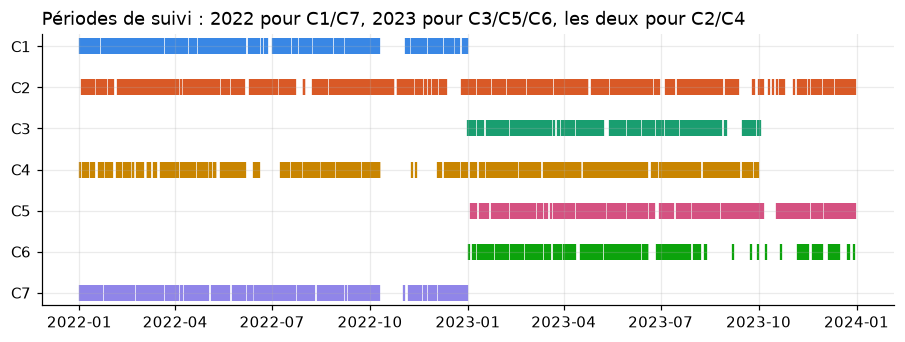

In [3]:
fig, ax = plt.subplots(figsize=(10, 3.2))
for i, c in enumerate(R.index):
    r = rides[rides.cyclist == c]
    ax.scatter(r["date"], [i] * len(r), marker="|", s=120, color=RIDER_COLORS[c])
ax.set_yticks(range(len(R)), [lab[c] for c in R.index]); ax.invert_yaxis()
ax.set_title("Périodes de suivi : 2022 pour C1/C7, 2023 pour C3/C5/C6, les deux pour C2/C4", loc="left")
plt.show()

In [4]:
# Source de la charge par coureur
src = rides.groupby(["cyclist", "load_source"]).size().unstack(fill_value=0)
src.index = [lab[c] for c in src.index]
(src.T / src.sum(axis=1)).T.style.format("{:.0%}")

load_source,FC (estimée),RPE (estimée),aucune,puissance
C1,20%,3%,1%,77%
C2,20%,4%,0%,76%
C3,14%,0%,0%,86%
C4,12%,1%,0%,87%
C5,8%,7%,2%,84%
C6,11%,7%,1%,81%
C7,10%,6%,1%,83%


## 2. Volet 1 : profil de performance
### 2.1 Courbe de puissance record (W/kg)
Maximum de la moyenne glissante sur chaque durée, toutes sorties confondues. En W/kg pour comparer des coureurs de 58 à 76 kg.

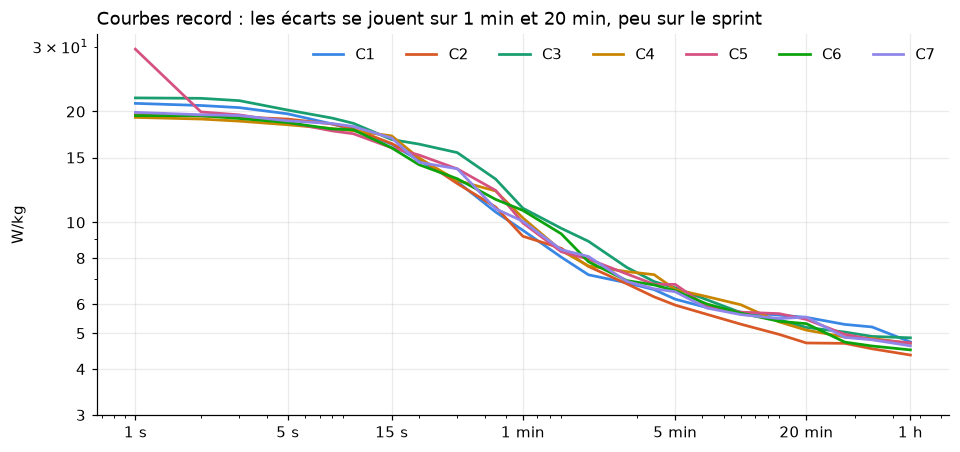

,5 s,1 min,5 min,20 min,60 min
C1,19.71,9.52,6.19,5.52,4.74
C2,19.08,9.17,5.96,4.71,4.36
C3,20.18,10.93,6.64,5.19,4.86
C4,18.41,10.28,6.58,5.10,4.70
C5,18.69,9.97,6.79,5.45,4.71
C6,18.66,10.78,6.53,5.31,4.51
C7,18.86,10.07,6.48,5.53,4.62


In [5]:
fig, ax = plt.subplots(figsize=(10, 4.5))
curves = {}
for c in R.index:
    cu = profile.record_curve(ride_mmp[ride_mmp.cyclist == c])
    curves[c] = cu
    cu = cu[cu.dur_s <= 3600]
    ax.plot(cu.dur_s, cu.p_wkg, color=RIDER_COLORS[c], lw=1.8, label=lab[c])
ax.set_xscale("log"); ax.set_yscale("log")
ticks = [1, 5, 15, 60, 300, 1200, 3600]
ax.set_xticks(ticks, ["1 s", "5 s", "15 s", "1 min", "5 min", "20 min", "1 h"])
ax.set_yticks([3, 4, 5, 6, 8, 10, 15, 20], [3, 4, 5, 6, 8, 10, 15, 20])
ax.set_ylabel("W/kg"); ax.legend(ncol=7, frameon=False, loc="upper right")
ax.set_title("Courbes record : les écarts se jouent sur 1 min et 20 min, peu sur le sprint", loc="left")
plt.show()

key = pd.DataFrame({lab[c]: curves[c].set_index("dur_s").loc[[5, 60, 300, 1200, 3600], "p_wkg"] for c in R.index}).T
key.columns = ["5 s", "1 min", "5 min", "20 min", "60 min"]
key.style.format("{:.2f}").background_gradient(cmap="Purples", axis=0)

### 2.2 FTP mensuelle
FTP = 0,95 × meilleur 20 min **sur une fenêtre glissante de 3 mois**. Vérification de la sensibilité au choix de fenêtre :
avec une fenêtre d'1 mois, un mois de coupure fait chuter la FTP et gonfle le TSS du mois suivant.

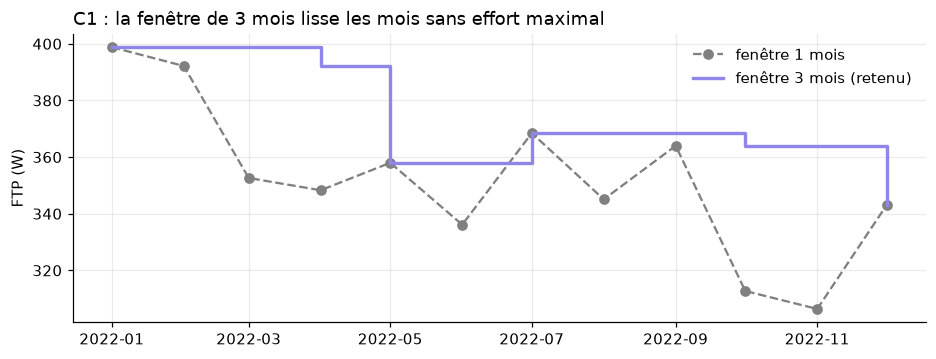

In [6]:
c = "cyclist1"
mm = ride_mmp[(ride_mmp.cyclist == c) & (ride_mmp.dur_s == 1200)].copy()
mm["month"] = mm.date.dt.to_period("M")
best = mm.groupby("month").p_w.max()
f3 = ftp[ftp.cyclist == c].set_index(ftp[ftp.cyclist == c].month.dt.to_period("M")).ftp_w
fig, ax = plt.subplots(figsize=(10, 3.4))
ax.plot(best.index.to_timestamp(), best * .95, "o--", color="grey", label="fenêtre 1 mois")
ax.step(f3.index.to_timestamp(), f3, where="post", color=METRIC["power"], lw=2.2, label="fenêtre 3 mois (retenu)")
ax.set_ylabel("FTP (W)"); ax.legend(frameon=False)
ax.set_title(f"{lab[c]} : la fenêtre de 3 mois lisse les mois sans effort maximal", loc="left")
plt.show()

### 2.3 Puissance critique et W′ (records 2 à 15 min)

In [7]:
rows = []
for c in R.index:
    cp = profile.fit_cp(curves[c])
    kg = R.loc[c, "weight_kg"]
    rows.append(dict(coureur=lab[c], kg=kg, CP_W=cp["cp_w"], CP_wkg=cp["cp_w"] / kg, Wprime_kJ=cp["wprime_j"] / 1000,
                     R2=cp["r2"], FTP_max_wkg=R.loc[c, "ftp_w_max"] / kg, ratio_CP_FTP=cp["cp_w"] / R.loc[c, "ftp_w_max"]))
cpt = pd.DataFrame(rows).set_index("coureur")
cpt

,kg,CP_W,CP_wkg,Wprime_kJ,R2,FTP_max_wkg,ratio_CP_FTP
coureur,,,,,,,
C1,76.0,402.43,5.30,20.04,1.00,5.25,1.01
C2,63.0,286.82,4.55,25.89,1.00,4.47,1.02
C3,65.0,318.44,4.90,32.06,1.00,4.93,0.99
C4,58.0,289.84,5.00,26.58,0.99,4.85,1.03
C5,65.0,338.49,5.21,23.65,1.00,5.18,1.01
C6,71.0,354.11,4.99,28.19,1.00,5.04,0.99
C7,74.0,374.75,5.06,26.76,1.00,5.26,0.96


**Lecture.** R² ≈ 1 partout : le modèle hyperbolique décrit bien les records 2-15 min. La CP est très proche de la FTP
estimée (ratio 0,96 à 1,03), ce qui donne confiance dans les deux estimations. W′ va de 20 kJ (C1) à 32 kJ (C3) :
C3 a la plus grosse réserve anaérobie, cohérent avec son profil de puncheur (meilleur 1 min : 10,9 W/kg).

Sur la courbe record, le sprint 5 s varie peu (18,4 à 20,2 W/kg, ~10 %) alors que le 1 min (9,2 à 10,9) et le 20 min
(4,7 à 5,5) varient de ~17-19 % : ce sont ces deux qualités qui différencient l'effectif.

Limite : les records viennent de sorties, pas de tests maximaux. Un record 3 min « non tenté » biaise l'ajustement.

In [8]:
sc = []
for c in R.index:
    s = profile.profile_scores(curves[c], R.loc[c, "weight_kg"]).set_index("dur_s")["score"]
    s.name = lab[c]; sc.append(s)
sc = pd.DataFrame(sc); sc.columns = ["5 s", "1 min", "5 min", "FTP"]
sc["profil"] = [profile.phenotype(profile.profile_scores(curves[c], R.loc[c, "weight_kg"]))[0] for c in R.index]
sc.style.format({k: "{:.0f}" for k in ["5 s", "1 min", "5 min", "FTP"]}).background_gradient(cmap="Purples", subset=["5 s", "1 min", "5 min", "FTP"], axis=1)

,5 s,1 min,5 min,FTP,profil
C1,69,66,73,74,Complet
C2,64,60,69,57,Grimpeur · PMA
C3,72,90,82,67,Puncheur
C4,59,79,81,65,Grimpeur · PMA
C5,62,74,85,73,Grimpeur · PMA
C6,61,88,80,70,Puncheur
C7,63,76,79,75,Grimpeur · PMA


## 3. Volet 2 : charge de travail
### 3.1 Les trois mesures de charge racontent-elles la même histoire ?
Comparaison, sortie par sortie, du TSS (externe), du TRIMP de Banister (FC) et du sRPE (ressenti).

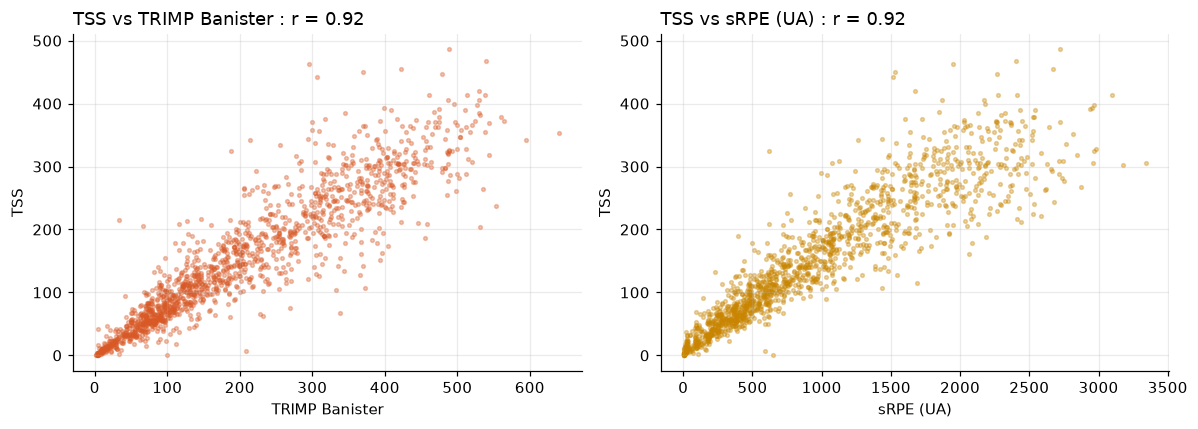

,trimp_banister,trimp_edwards,srpe
C1,0.95,0.96,0.93
C2,0.95,0.95,0.92
C3,0.96,0.95,0.94
C4,0.93,0.93,0.96
C5,0.92,0.93,0.93
C6,0.83,0.84,0.81
C7,0.94,0.92,0.91


In [9]:
both = rides.dropna(subset=["tss", "trimp_banister", "srpe"])
fig, axs = plt.subplots(1, 2, figsize=(11, 4))
for ax, col, name, colr in [(axs[0], "trimp_banister", "TRIMP Banister", METRIC["hr"]), (axs[1], "srpe", "sRPE (UA)", METRIC["srpe"])]:
    ax.scatter(both[col], both["tss"], s=6, alpha=.35, color=colr)
    r = both[[col, "tss"]].corr().iloc[0, 1]
    ax.set_xlabel(name); ax.set_ylabel("TSS"); ax.set_title(f"TSS vs {name} : r = {r:.2f}", loc="left")
plt.tight_layout(); plt.show()

corr = both.groupby("cyclist")[["tss", "trimp_banister", "srpe", "trimp_edwards"]].corr().xs("tss", level=1)[["trimp_banister", "trimp_edwards", "srpe"]]
corr.index = [lab[c] for c in corr.index]; corr

**Lecture.** Les trois charges sont très liées (r = 0,92 entre TSS et TRIMP, 0,92 entre TSS et sRPE ; par coureur 0,81 à 0,96,
C6 étant le moins cohérent), ce qui justifie la conversion TRIMP → TSS pour les sorties sans capteur. La FC de repos n'est connue que pour C4 (50 bpm par hypothèse ailleurs) : le TRIMP de Banister des autres est donc
approximatif, mais l'erreur est absorbée par le coefficient de conversion propre à chaque coureur.

### 3.2 Forme (CTL), fatigue (ATL), fraîcheur (TSB)

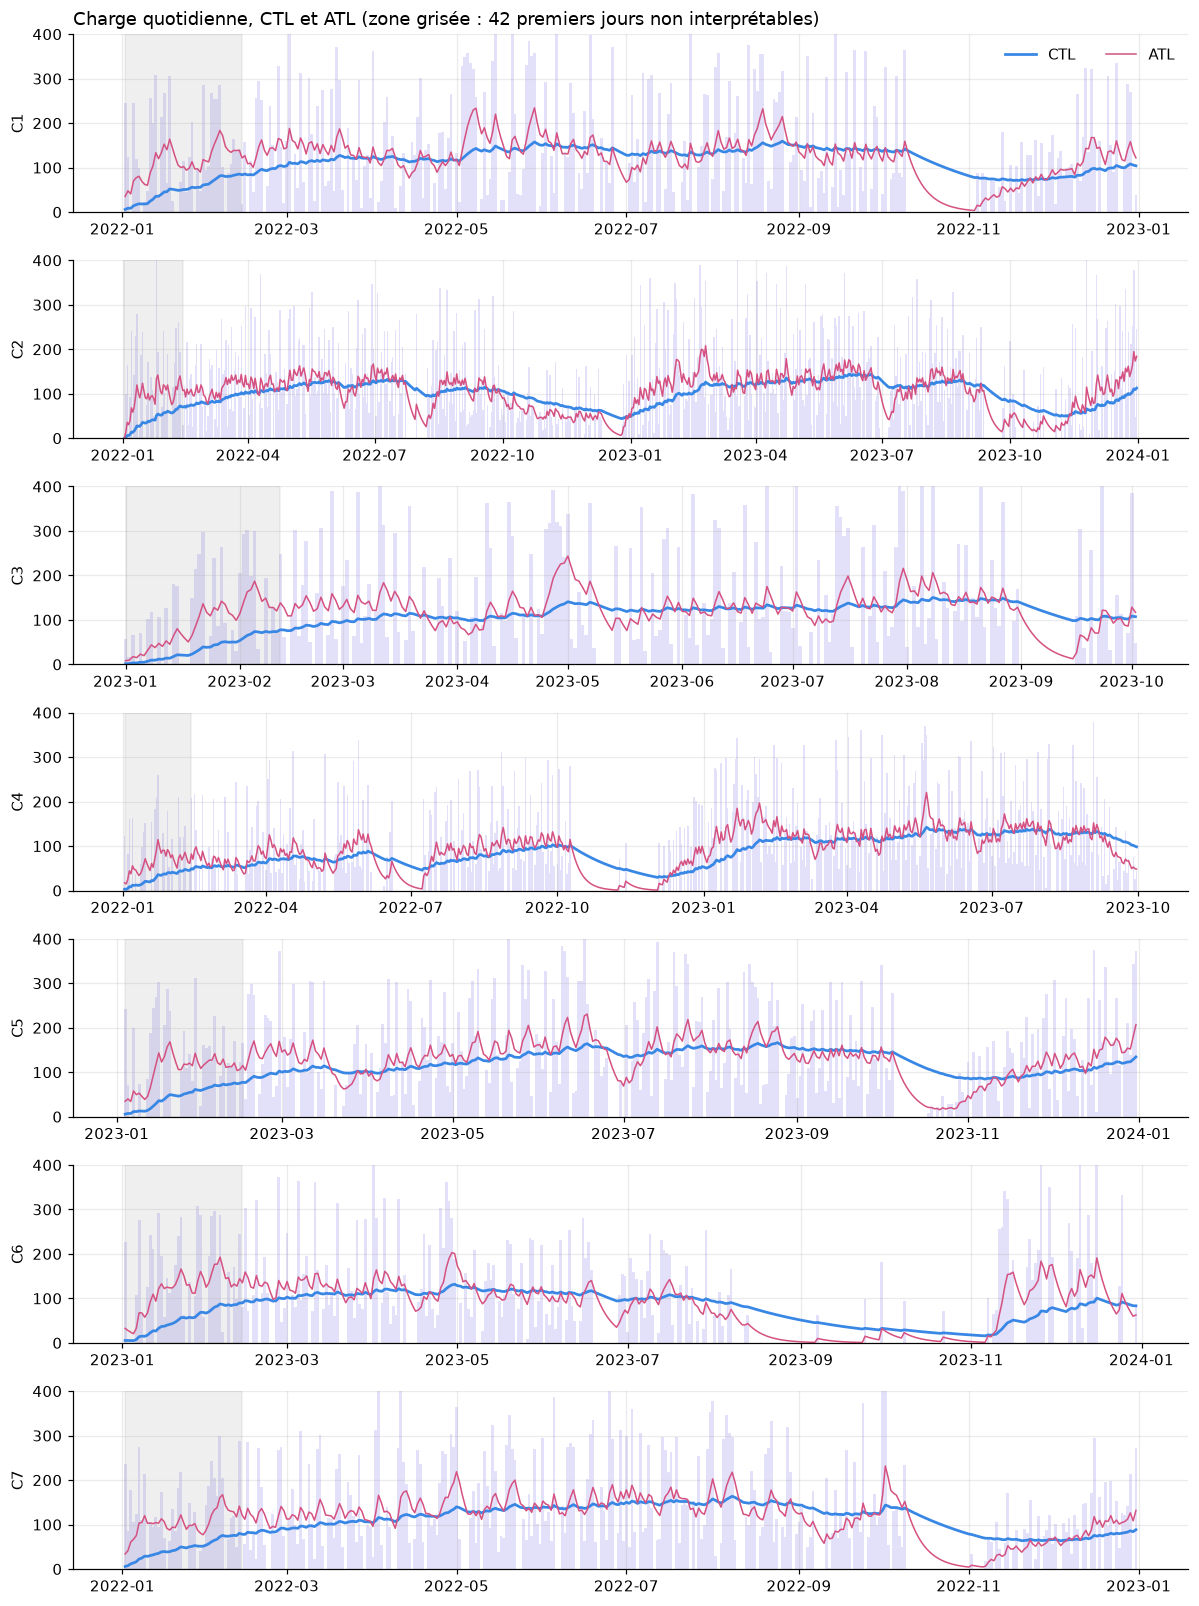

In [10]:
fig, axs = plt.subplots(len(R), 1, figsize=(11, 2.1 * len(R)), sharex=False)
for ax, c in zip(axs, R.index):
    d = daily[daily.cyclist == c]
    ax.bar(d.date, d.load, color=METRIC["power"], alpha=.25, width=1)
    ax.plot(d.date, d.ctl, color=METRIC["ctl"], lw=1.8, label="CTL")
    ax.plot(d.date, d.atl, color=METRIC["atl"], lw=1, label="ATL")
    ax.axvspan(d.date.min(), d.date.min() + pd.Timedelta(days=42), color="grey", alpha=.12)
    ax.set_ylabel(lab[c]); ax.set_ylim(0, 400)
axs[0].legend(ncol=2, frameon=False, loc="upper right")
axs[0].set_title("Charge quotidienne, CTL et ATL (zone grisée : 42 premiers jours non interprétables)", loc="left")
plt.tight_layout(); plt.show()

In [11]:
# Saisonnalité commune : CTL moyenne par mois de saison, en relatif à la moyenne du coureur
d = daily[~daily.warmup].copy()
d["mois"] = d.date.dt.month
rel = d.groupby(["cyclist", "mois"]).ctl.mean().unstack()
rel = rel.div(rel.mean(axis=1), axis=0) * 100
rel.index = [lab[c] for c in rel.index]
rel.style.format("{:.0f}").background_gradient(cmap="Blues", axis=None)

mois,1,2,3,4,5,6,7,8,9,10,11,12
C1,nan,78,98,99,116,122,110,121,119,98,62,77
C2,69,95,105,116,127,130,121,114,108,81,64,71
C3,nan,74,91,95,109,108,111,124,95,93,nan,nan
C4,89,107,100,110,118,120,112,122,125,99,52,45
C5,nan,73,85,89,106,122,119,127,121,93,73,91
C6,nan,115,131,140,144,130,121,90,46,30,50,103
C7,nan,73,88,103,117,123,130,131,112,100,59,64


**Lecture.** En relatif (100 = CTL moyenne du coureur), tout le monde monte en charge au printemps et culmine en été ;
C6 fait exception : sa forme culmine tôt (mars-avril, ~130-140 % de sa moyenne) puis s'effondre dès l'automne (30-50 %),
fin de saison anticipée ou coupure. C'est la raison de l'alignement par mois de saison dans l'app.

### 3.3 Distribution d'intensité (zones de puissance, % de la FTP du mois)

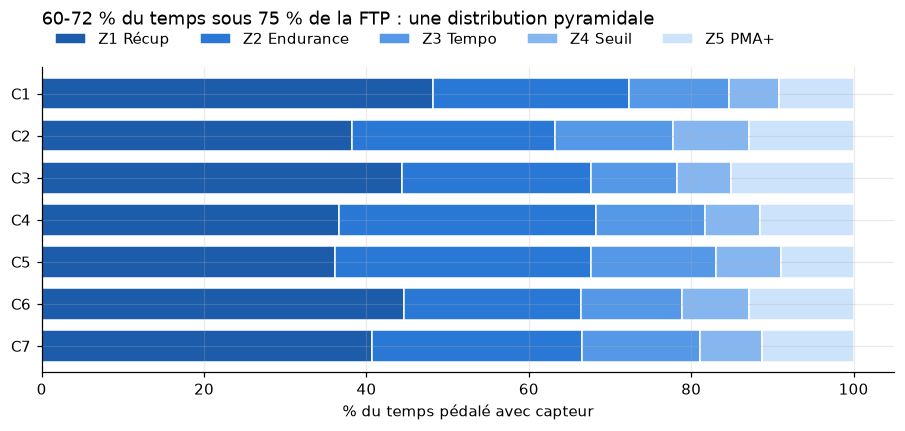

In [12]:
z = rides.groupby("cyclist")[[f"pz{i}_s" for i in range(1, 6)]].sum()
z = z.div(z.sum(axis=1), axis=0) * 100
z.index = [lab[c] for c in z.index]; z.columns = [n for n, *_ in POWER_ZONES]
ax = z.plot.barh(stacked=True, color=ZONE_COLORS, figsize=(10, 3.6), width=.75, edgecolor="white")
ax.invert_yaxis(); ax.set_xlabel("% du temps pédalé avec capteur"); ax.legend(ncol=5, frameon=False, bbox_to_anchor=(0, 1.02), loc="lower left")
ax.set_title("60-72 % du temps sous 75 % de la FTP : une distribution pyramidale", loc="left", pad=28)
plt.show()

## 4. Bien-être (Hooper) et charge : liens descriptifs
Corrélation, par coureur, entre le Hooper du jour et la charge des jours précédents (j-1, somme 3 j, somme 7 j), puis la TSB.
*Données psychométriques fictives : à interpréter comme une démonstration de méthode.*

In [13]:
res = []
for c in R.index:
    d = daily[(daily.cyclist == c) & ~daily.warmup].set_index("date")
    x = pd.DataFrame({"hooper": d.hooper, "charge_j-1": d.load.shift(1), "charge_3j": d.load.shift(1).rolling(3).sum(),
                      "charge_7j": d.load.shift(1).rolling(7).sum(), "tsb_j-1": d.tsb.shift(1),
                      "fatigue_item": d.fatigue})
    cc = x.corr()["hooper"].drop("hooper")
    cc.name = lab[c]; res.append(cc)
pd.DataFrame(res).style.format("{:+.2f}").background_gradient(cmap="RdBu_r", vmin=-.6, vmax=.6)

,charge_j-1,charge_3j,charge_7j,tsb_j-1,fatigue_item
C1,+0.65,+0.64,+0.68,-0.71,+0.86
C2,+0.35,+0.42,+0.44,-0.41,+0.81
C3,+0.64,+0.65,+0.70,-0.77,+0.91
C4,+0.67,+0.70,+0.77,-0.69,+0.91
C5,+0.67,+0.65,+0.64,-0.61,+0.88
C6,+0.66,+0.67,+0.71,-0.52,+0.91
C7,+0.67,+0.63,+0.60,-0.66,+0.88


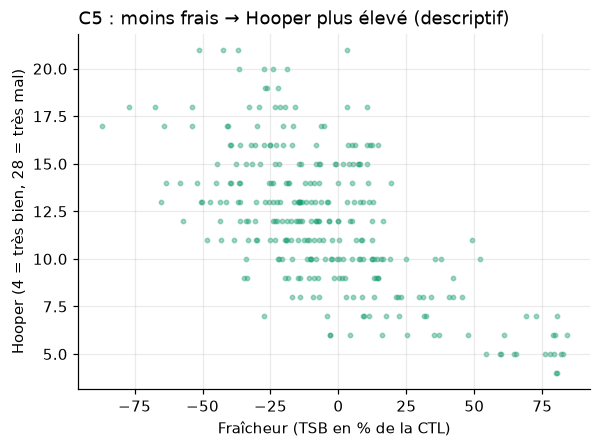

In [14]:
c = "cyclist5"
d = daily[(daily.cyclist == c) & ~daily.warmup]
fig, ax = plt.subplots(figsize=(6, 4.2))
ax.scatter(d.tsb_pct, d.hooper, s=8, alpha=.4, color=METRIC["hooper"])
ax.set_xlabel("Fraîcheur (TSB en % de la CTL)"); ax.set_ylabel("Hooper (4 = très bien, 28 = très mal)")
ax.set_title(f"{lab[c]} : moins frais → Hooper plus élevé (descriptif)", loc="left")
plt.show()

In [15]:
# Combien d'alertes le système déclencherait-il ? (jours en orange / rouge par coureur)
al = []
for c in R.index:
    d = daily[(daily.cyclist == c) & ~daily.warmup]
    st = [tracking.tsb_band(t)[1] for t in d.tsb_pct]
    hz = [tracking.hooper_status(z)[1] for z in d.hooper_z]
    al.append(dict(coureur=lab[c], jours=len(d),
                   tsb_orange=np.mean([s == "warning" for s in st]), tsb_rouge=np.mean([s == "critical" for s in st]),
                   hooper_orange=np.mean([s == "warning" for s in hz]), hooper_rouge=np.mean([s == "critical" for s in hz])))
pd.DataFrame(al).set_index("coureur").style.format({k: "{:.0%}" for k in ["tsb_orange", "tsb_rouge", "hooper_orange", "hooper_rouge"]})

,jours,tsb_orange,tsb_rouge,hooper_orange,hooper_rouge
coureur,,,,,
C1,322,18%,4%,13%,6%
C2,687,13%,7%,9%,5%
C3,233,16%,8%,12%,5%
C4,595,16%,10%,14%,6%
C5,320,18%,4%,13%,6%
C6,321,11%,12%,10%,5%
C7,322,19%,3%,16%,5%


**Lecture.** Le Hooper suit nettement la charge récente (r ≈ +0,6 à +0,7 avec la charge des 7 jours précédents, sauf C2 ≈ +0,4) :
plus la charge monte, plus le score se dégrade. Lien descriptif sur des données fictives, pas une preuve de cause.

**Choix des seuils de fraîcheur.** Avec les seuils absolus classiques (TSB < −30 = rouge), 15 à 25 % des jours passaient au rouge :
trop pour une alerte. On utilise donc la fraîcheur relative (TSB / CTL) : orange sous −25 %, rouge sous −50 %.
Le rouge tombe à 3-12 % des jours (tableau ci-dessus), le Hooper au rouge reste autour de 5 %.

## 5. À retenir et pistes
- **Profil** : C3 et C6 se détachent sur 1 min (puncheurs) ; C1 est le plus complet ; C7 et C1 sont les plus forts au seuil (≈ 5,5 W/kg sur 20 min).
- **Charge** : la charge unifiée (TSS / TRIMP / sRPE convertis) évite de « perdre » ~20 % des sorties sans capteur.
- **Bien-être** : le Hooper suit la charge des 7 derniers jours (r ≈ 0,6-0,7) mais avec un niveau de base propre à chacun, d'où des alertes calculées par rapport à l'habitude du coureur.
- **Alertes** : fraîcheur relative à la CTL plutôt que TSB absolu, sinon 1 jour sur 5 est rouge.

Pistes : 
1. valider les seuils de fraîcheur avec le staff (−25 % / −50 % de la CTL) ;
2. utiliser la FC de repos de C4 (variabilité quotidienne) comme indicateur de fatigue ;
3. comparer le découplage cardiaque indoor / outdoor ;
4. relier les records mensuels (MMP) à la CTL du mois précédent (descriptif).